In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("M:\Data Analyst Projects\Customer Shopping Behaviour\customer_shopping_behavior.csv")

print(df.shape)
print(df.head())

(3900, 19)
   customer_id  age gender item_purchased  category  purchase_amount  \
0            1   55   Male         Blouse  Clothing               53   
1            2   19   Male        Sweater  Clothing               64   
2            3   50   Male          Jeans  Clothing               73   
3            4   21   Male        Sandals  Footwear               90   
4            5   45   Male         Blouse  Clothing               49   

        location size      color  season  review_rating subscription_status  \
0       Kentucky    L       Gray  Winter            3.1                 Yes   
1          Maine    L     Maroon  Winter            3.1                 Yes   
2  Massachusetts    S     Maroon  Spring            3.1                 Yes   
3   Rhode Island    M     Maroon  Spring            3.5                 Yes   
4         Oregon    M  Turquoise  Spring            2.7                 Yes   

   shipping_type discount_applied promo_code_used  previous_purchases  \
0       

In [3]:
numeric_features = [
    'purchase_amount',
    'previous_purchases',
    'review_rating'
]

categorical_features = [
    'frequency_of_purchases'
]

X = df[numeric_features + categorical_features]

In [4]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),

        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ]
)

X_scaled = preprocessor.fit_transform(X)

print("Preprocessing completed")

Preprocessing completed


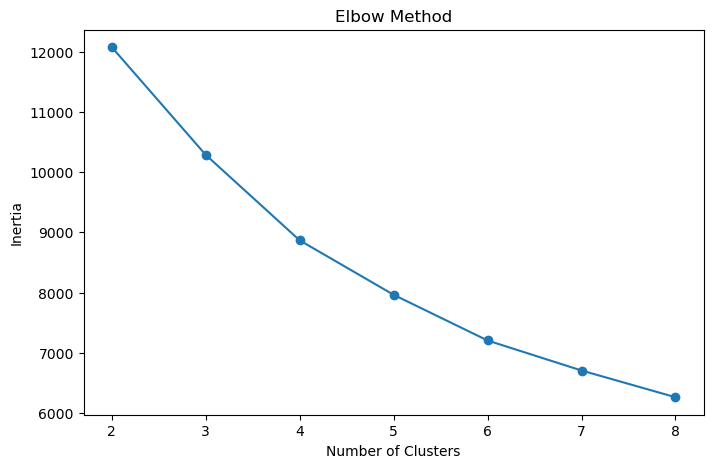

In [5]:
inertia = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(2, 9), inertia, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.show()

In [6]:
for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(k, round(score, 3))

2 0.185
3 0.173
4 0.185
5 0.176
6 0.183
7 0.172
8 0.165


In [7]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster_ID'] = kmeans.fit_predict(X_scaled)

print(df[['customer_id', 'Cluster_ID']].head())

   customer_id  Cluster_ID
0            1           1
1            2           1
2            3           1
3            4           0
4            5           1


In [8]:
cluster_profile = df.groupby('Cluster_ID').agg(
    Customer_Count=('customer_id', 'count'),
    Average_Purchase=('purchase_amount', 'mean'),
    Average_Previous_Purchases=('previous_purchases', 'mean'),
    Average_Rating=('review_rating', 'mean')
).round(2)

print(cluster_profile)

            Customer_Count  Average_Purchase  Average_Previous_Purchases  \
Cluster_ID                                                                 
0                     1240             81.01                       26.49   
1                     1477             60.44                       24.90   
2                     1183             36.65                       24.73   

            Average_Rating  
Cluster_ID                  
0                     4.27  
1                     3.00  
2                     4.16  


In [9]:
ordered_clusters = (
    df.groupby('Cluster_ID')['purchase_amount']
    .mean()
    .sort_values()
    .index
)

segment_names = [
    'Low Spend Segment',
    'Medium Spend Segment',
    'High Spend Segment'
]

segment_mapping = dict(zip(
    ordered_clusters,
    segment_names
))

df['Cluster_Label'] = df['Cluster_ID'].map(segment_mapping)

print(df[['customer_id', 'Cluster_ID', 'Cluster_Label']].head())

   customer_id  Cluster_ID         Cluster_Label
0            1           1  Medium Spend Segment
1            2           1  Medium Spend Segment
2            3           1  Medium Spend Segment
3            4           0    High Spend Segment
4            5           1  Medium Spend Segment


In [10]:
df.to_csv(
    "customer_behavior_with_clusters.csv",
    index=False
)

print("Customer segmentation dataset exported successfully!")

Customer segmentation dataset exported successfully!
